# EV Charging — Analysis on the Cleaned Data
Model evaluation & comparison · handling class imbalance · explainable AI (SHAP & LIME) · data visualization · Python & scikit-learn

**Data:** `ChargingRecords_preprocessed.csv` (cleaned). **Targets:** `Demand` (kWh) for regression, and `HighDemand` = Demand ≥ median for classification.

In [1]:
# Run once if needed:  %pip install xgboost lightgbm imbalanced-learn shap lime
RS = 42
import sys, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.pipeline import Pipeline as ImbPipeline
try:
    import shap
except Exception:   # a broken optional pyspark install (common on Windows) can break shap's import
    for m in [k for k in sys.modules if k.split('.')[0] in ('pyspark', 'shap')]: del sys.modules[m]
    sys.modules['pyspark'] = None; import shap
from lime.lime_tabular import LimeTabularExplainer
sns.set_theme(style='whitegrid'); shap.initjs() if False else None

## 1. Load and check the cleaned data

In [2]:
df = pd.read_csv(r"D:\HCL_PROJECTS\EV_Charging_Demand_Analysis\ChargingRecords_preprocessed.csv")
print(df.shape, '| missing:', int(df.isna().sum().sum()), '| duplicates:', int(df.duplicated().sum()), '| Duration<=0:', int((df.Duration<=0).sum()))
df['Start'] = pd.to_datetime(df['StartTimestamp'])
h = df['Start'].dt.hour + df['Start'].dt.minute/60
df['HourSin'], df['HourCos'] = np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24)
df['IsWeekend'] = df['IsWeekend'].astype(int); df['Overnight'] = df['CrossesMidnight'].astype(int)
THR = df['Demand'].median(); df['HighDemand'] = (df['Demand'] >= THR).astype(int)
num_cols = ['Duration','StartHour','HourSin','HourCos','DayOfWeek','IsWeekend','Month','Overnight','ChargerType','ChargerCompany']
cat_cols = ['Location']; FEATURES = num_cols + cat_cols
print(f'Median demand threshold = {THR:.2f} kWh')
df[FEATURES + ['Demand','HighDemand']].describe().T.round(2)

(72031, 30) | missing: 0 | duplicates: 0 | Duration<=0: 0
Median demand threshold = 14.26 kWh


,count,mean,std,min,25%,50%,75%,max
Duration,72031.0,152.46,145.89,1.00,41.00,113.00,202.00,1439.0
StartHour,72031.0,14.61,5.07,0.00,11.00,16.00,19.00,23.0
HourSin,72031.0,-0.35,0.65,-1.00,-0.93,-0.62,0.15,1.0
HourCos,72031.0,-0.19,0.64,-1.00,-0.79,-0.31,0.35,1.0
DayOfWeek,72031.0,2.93,1.95,0.00,1.00,3.00,5.00,6.0
IsWeekend,72031.0,0.26,0.44,0.00,0.00,0.00,1.00,1.0
Month,72031.0,6.25,3.25,1.00,4.00,6.00,9.00,12.0
Overnight,72031.0,0.15,0.36,0.00,0.00,0.00,0.00,1.0
ChargerType,72031.0,0.20,0.40,0.00,0.00,0.00,0.00,1.0
ChargerCompany,72031.0,0.63,0.48,0.00,0.00,1.00,1.00,1.0


## 2. Data visualization
Features exclude identifiers (`UserID`, `ChargerID`) and post-session fields (`ElapsedMin`, `IdleMin`, `EndHour`, `FlagIdleOver30`).

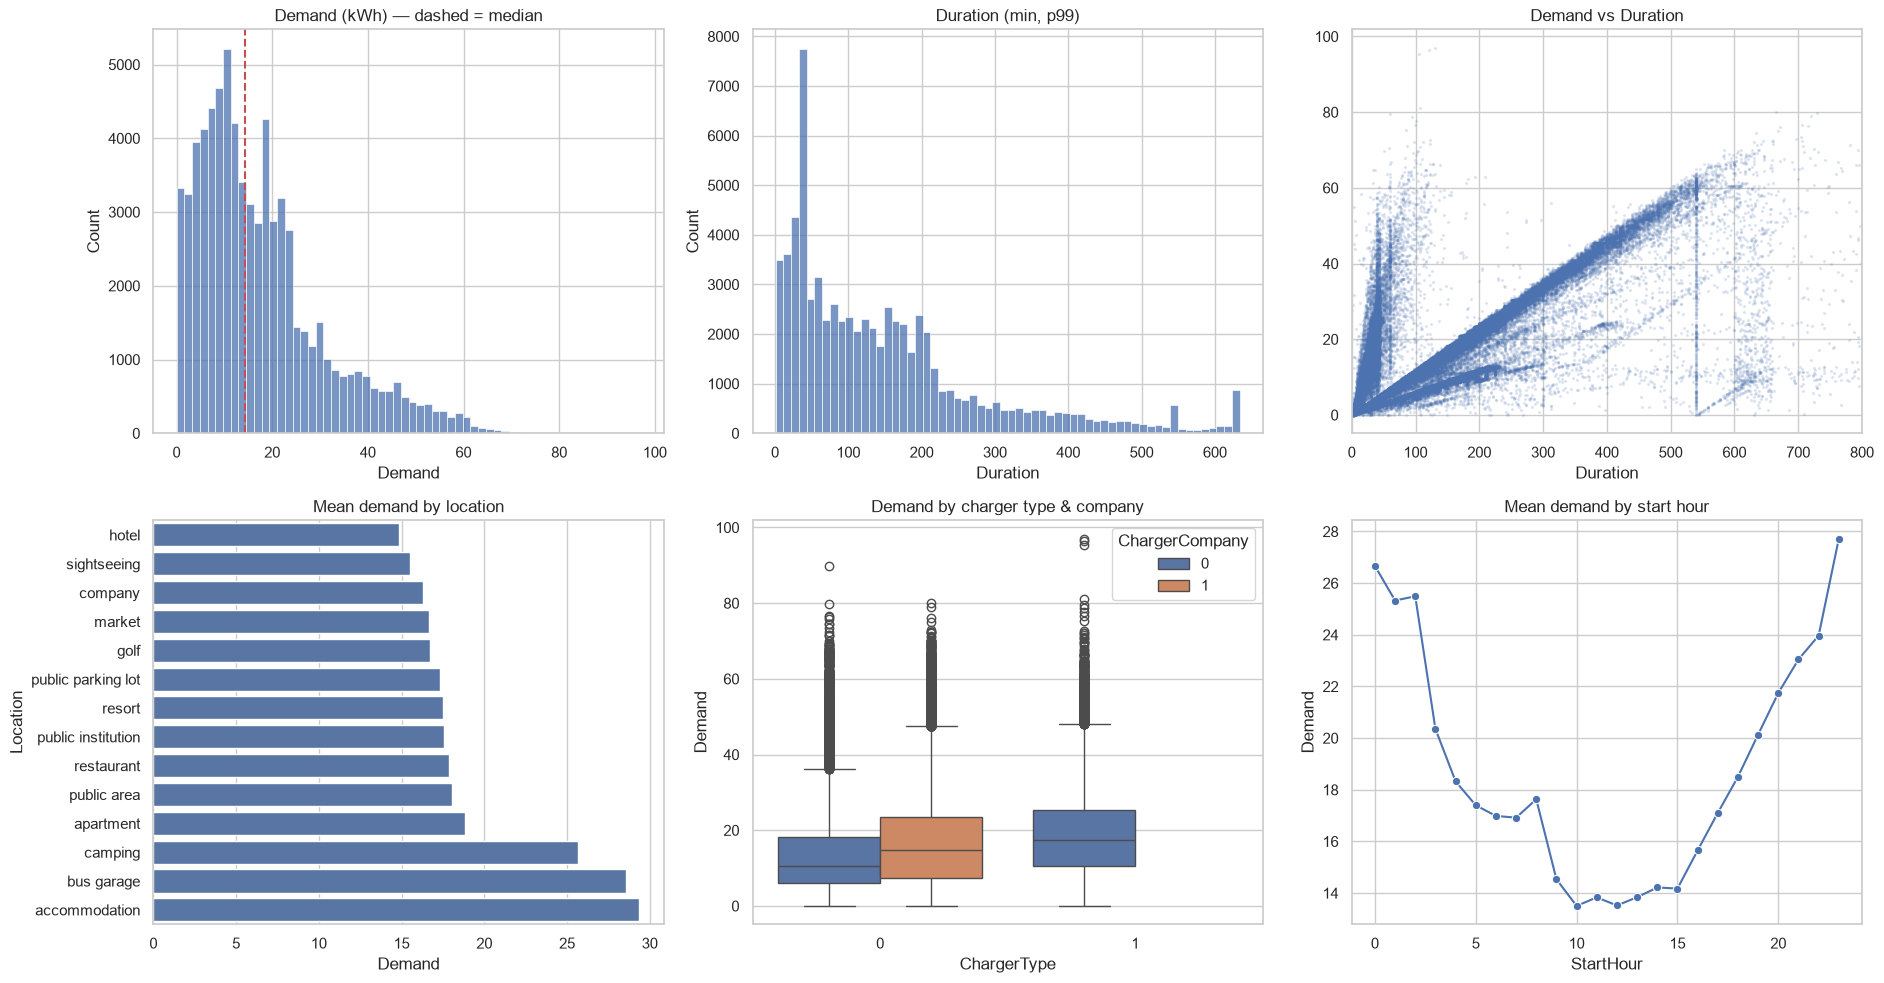

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(19, 10))
sns.histplot(df['Demand'], bins=60, ax=ax[0,0]); ax[0,0].axvline(THR, color='r', ls='--'); ax[0,0].set_title('Demand (kWh) — dashed = median')
sns.histplot(df['Duration'].clip(upper=df['Duration'].quantile(.99)), bins=60, ax=ax[0,1]); ax[0,1].set_title('Duration (min, p99)')
ax[0,2].scatter(df['Duration'], df['Demand'], s=2, alpha=.12); ax[0,2].set_xlim(0, 800); ax[0,2].set_title('Demand vs Duration'); ax[0,2].set_xlabel('Duration')
order = df.groupby('Location')['Demand'].mean().sort_values().index
sns.barplot(data=df, y='Location', x='Demand', order=order, errorbar=None, ax=ax[1,0]); ax[1,0].set_title('Mean demand by location')
sns.boxplot(data=df, x='ChargerType', y='Demand', hue='ChargerCompany', ax=ax[1,1]); ax[1,1].set_title('Demand by charger type & company')
sns.lineplot(data=df.groupby('StartHour')['Demand'].mean().reset_index(), x='StartHour', y='Demand', marker='o', ax=ax[1,2]); ax[1,2].set_title('Mean demand by start hour')
plt.tight_layout(); plt.show()

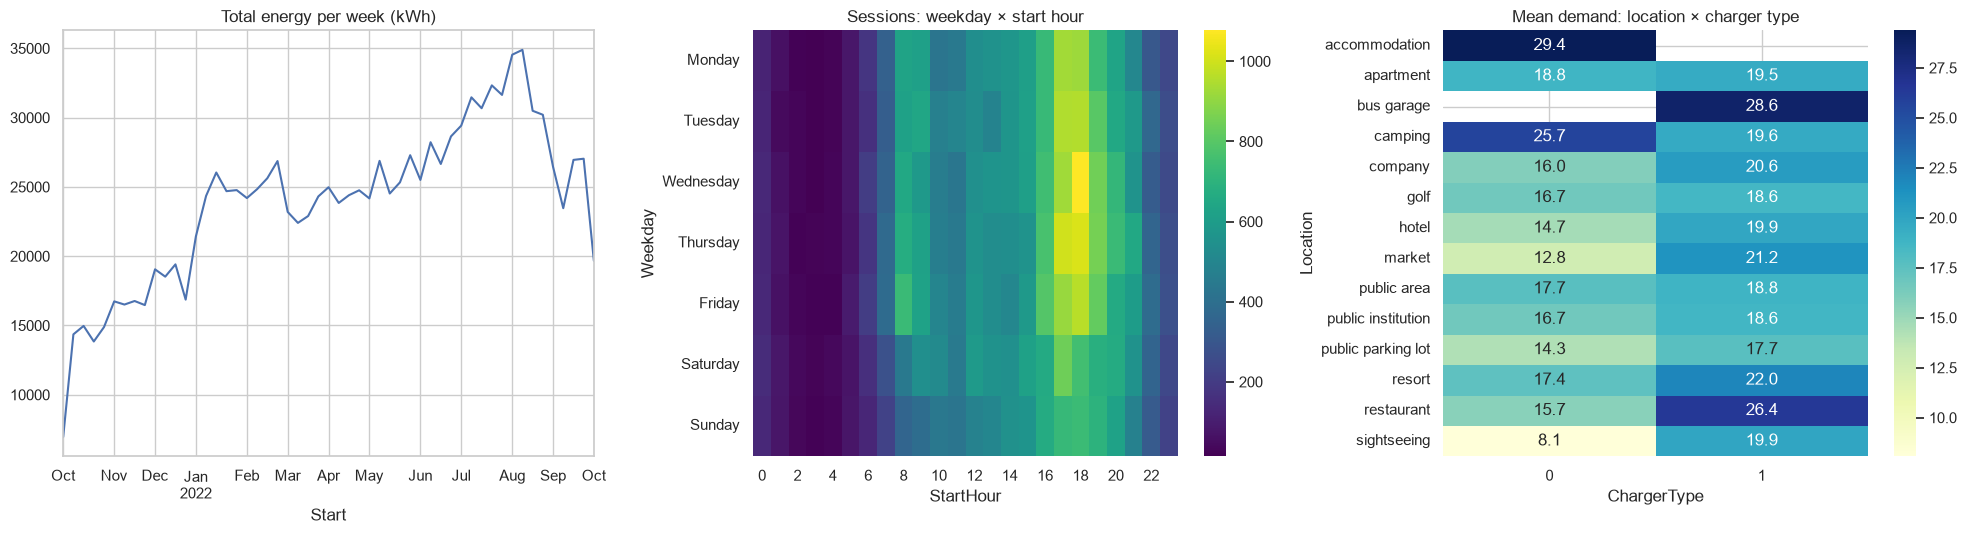

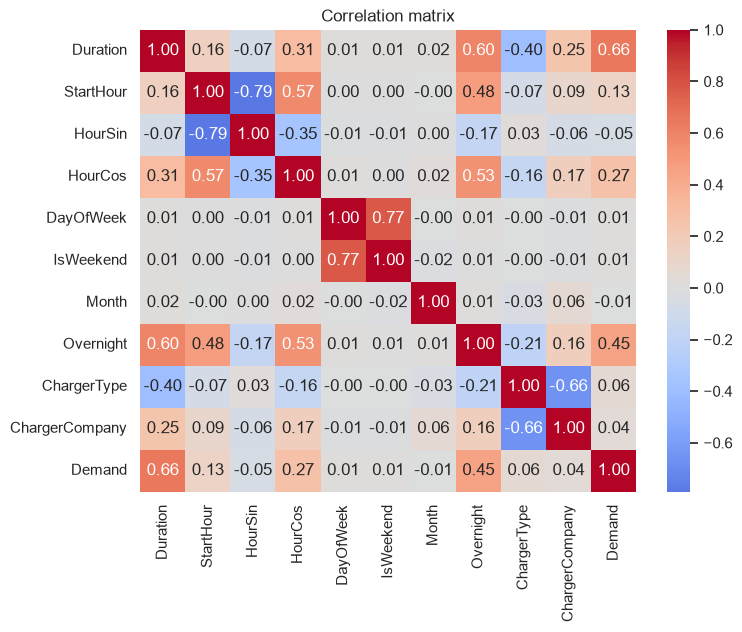

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
m = df.set_index('Start').resample('W')['Demand'].agg(['sum','size'])
m['sum'].plot(ax=ax[0]); ax[0].set_title('Total energy per week (kWh)')
order_d = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
sns.heatmap(df.pivot_table(index='Weekday', columns='StartHour', values='Demand', aggfunc='size').reindex(order_d), cmap='viridis', ax=ax[1]); ax[1].set_title('Sessions: weekday × start hour')
sns.heatmap(df.pivot_table(index='Location', columns='ChargerType', values='Demand', aggfunc='mean'), annot=True, fmt='.1f', cmap='YlGnBu', ax=ax[2]); ax[2].set_title('Mean demand: location × charger type')
plt.tight_layout(); plt.show()
plt.figure(figsize=(8,6)); sns.heatmap(df[num_cols+['Demand']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Correlation matrix'); plt.show()

## 3. Model evaluation & comparison
Shared preprocessing (one-hot `Location`, scaling for distance/linear models), 20% hold-out test set plus cross-validation on the training set.

In [5]:
def prep(scale=False, nc=num_cols):
    return ColumnTransformer([('num', StandardScaler() if scale else 'passthrough', nc), ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
FAST = True   # True: 3-fold CV and 12k-row SVM sample. False: 5-fold CV, 30k-row SVM sample (slower)
K = 3 if FAST else 5; SVM_N = 12000 if FAST else 30000

reg_models = {
 'Linear Regression': Pipeline([('p', prep(True)), ('m', LinearRegression())]),
 'Decision Tree': Pipeline([('p', prep()), ('m', DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=RS))]),
 'Random Forest': Pipeline([('p', prep()), ('m', RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=RS))]),
 'Gradient Boosting': Pipeline([('p', prep()), ('m', GradientBoostingRegressor(n_estimators=100, subsample=0.5, max_depth=4, random_state=RS))]),
 'XGBoost': Pipeline([('p', prep()), ('m', XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=.8, colsample_bytree=.8, n_jobs=-1, random_state=RS))]),
 'LightGBM': Pipeline([('p', prep()), ('m', LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8, n_jobs=-1, random_state=RS, verbose=-1))]),
}
Xtr, Xte, ytr, yte = train_test_split(df[FEATURES], df['Demand'], test_size=0.2, random_state=RS)
rows, reg_fit = [], {}
for n, p in reg_models.items():
    cv = cross_validate(p, Xtr, ytr, cv=KFold(K, shuffle=True, random_state=RS), scoring='r2', n_jobs=-1)
    p.fit(Xtr, ytr); reg_fit[n] = p; pr = p.predict(Xte); mse = mean_squared_error(yte, pr)
    rows.append(dict(Model=n, MAE=mean_absolute_error(yte, pr), MSE=mse, RMSE=np.sqrt(mse), R2=r2_score(yte, pr), CV_R2=cv['test_score'].mean(), CV_std=cv['test_score'].std()))
reg_res = pd.DataFrame(rows).set_index('Model').sort_values('RMSE')
best_reg = reg_res.index[0]; print('REGRESSION — best model:', best_reg); reg_res.round(4)

REGRESSION — best model: XGBoost


,MAE,MSE,RMSE,R2,CV_R2,CV_std
Model,,,,,,
XGBoost,3.3057,34.2512,5.8525,0.8114,0.8027,0.0044
LightGBM,3.3567,34.5981,5.8820,0.8095,0.8010,0.0047
Random Forest,3.2845,35.4689,5.9556,0.8047,0.7951,0.0030
Gradient Boosting,3.5386,37.6998,6.1400,0.7924,0.7844,0.0045
Decision Tree,3.5551,39.4280,6.2792,0.7829,0.7714,0.0046
Linear Regression,5.5096,71.5403,8.4581,0.6060,0.5768,0.0056


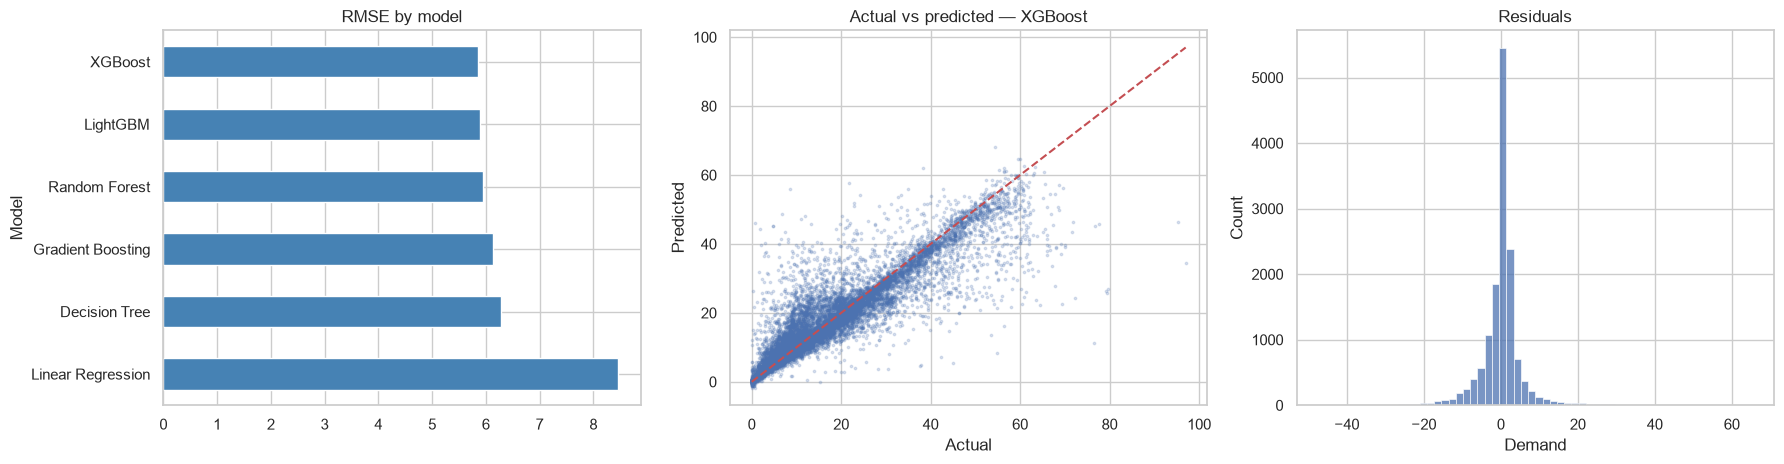

In [6]:
pr = reg_fit[best_reg].predict(Xte)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
reg_res['RMSE'].sort_values(ascending=False).plot.barh(ax=ax[0], color='steelblue'); ax[0].set_title('RMSE by model')
ax[1].scatter(yte, pr, s=3, alpha=.2); ax[1].plot([0, yte.max()], [0, yte.max()], 'r--'); ax[1].set_title(f'Actual vs predicted — {best_reg}'); ax[1].set_xlabel('Actual'); ax[1].set_ylabel('Predicted')
sns.histplot(yte-pr, bins=60, ax=ax[2]); ax[2].set_title('Residuals'); plt.tight_layout(); plt.show()

In [7]:
clf_models = {
 'Logistic Regression': Pipeline([('p', prep(True)), ('m', LogisticRegression(max_iter=2000, random_state=RS))]),
 'Decision Tree': Pipeline([('p', prep()), ('m', DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=RS))]),
 'Random Forest': Pipeline([('p', prep()), ('m', RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=RS))]),
 'KNN': Pipeline([('p', prep(True)), ('m', KNeighborsClassifier(n_neighbors=25, n_jobs=-1))]),
 'SVM': Pipeline([('p', prep(True)), ('m', SVC(kernel='rbf', random_state=RS))]),
 'XGBoost': Pipeline([('p', prep()), ('m', XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=.8, colsample_bytree=.8, n_jobs=-1, random_state=RS, eval_metric='logloss'))]),
 'LightGBM': Pipeline([('p', prep()), ('m', LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8, n_jobs=-1, random_state=RS, verbose=-1))]),
}
def cscore(p, Xt, yt):
    pr = p.predict(Xt); s = p.predict_proba(Xt)[:,1] if hasattr(p, 'predict_proba') else p.decision_function(Xt)
    return dict(Accuracy=accuracy_score(yt,pr), Precision=precision_score(yt,pr, zero_division=0), Recall=recall_score(yt,pr), F1=f1_score(yt,pr), ROC_AUC=roc_auc_score(yt,s), PR_AUC=average_precision_score(yt,s))
def fit_clf(n, p, Xa, ya):
    if n == 'SVM' and len(Xa) > SVM_N: i = Xa.sample(SVM_N, random_state=RS).index; return p.fit(Xa.loc[i], ya.loc[i])
    return p.fit(Xa, ya)
Xtr, Xte, ytr, yte = train_test_split(df[FEATURES], df['HighDemand'], test_size=0.2, stratify=df['HighDemand'], random_state=RS)
rows, clf_fit = [], {}
for n, p in clf_models.items():
    fit_clf(n, p, Xtr, ytr); clf_fit[n] = p; rows.append({'Model': n, **cscore(p, Xte, yte)})
clf_res = pd.DataFrame(rows).set_index('Model').sort_values('ROC_AUC', ascending=False)
best_clf = clf_res.index[0]; print('CLASSIFICATION — best model:', best_clf); clf_res.round(4)

CLASSIFICATION — best model: XGBoost


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
XGBoost,0.9000,0.8701,0.9406,0.9039,0.9621,0.9549
LightGBM,0.9008,0.8716,0.9402,0.9046,0.9619,0.9546
Random Forest,0.8997,0.8656,0.9464,0.9042,0.9593,0.9511
Decision Tree,0.8967,0.8730,0.9285,0.8999,0.9532,0.9389
SVM,0.8729,0.8331,0.9327,0.8801,0.9366,0.9132
KNN,0.8258,0.8004,0.8681,0.8329,0.9133,0.9007
Logistic Regression,0.8409,0.8237,0.8676,0.8451,0.9113,0.8662


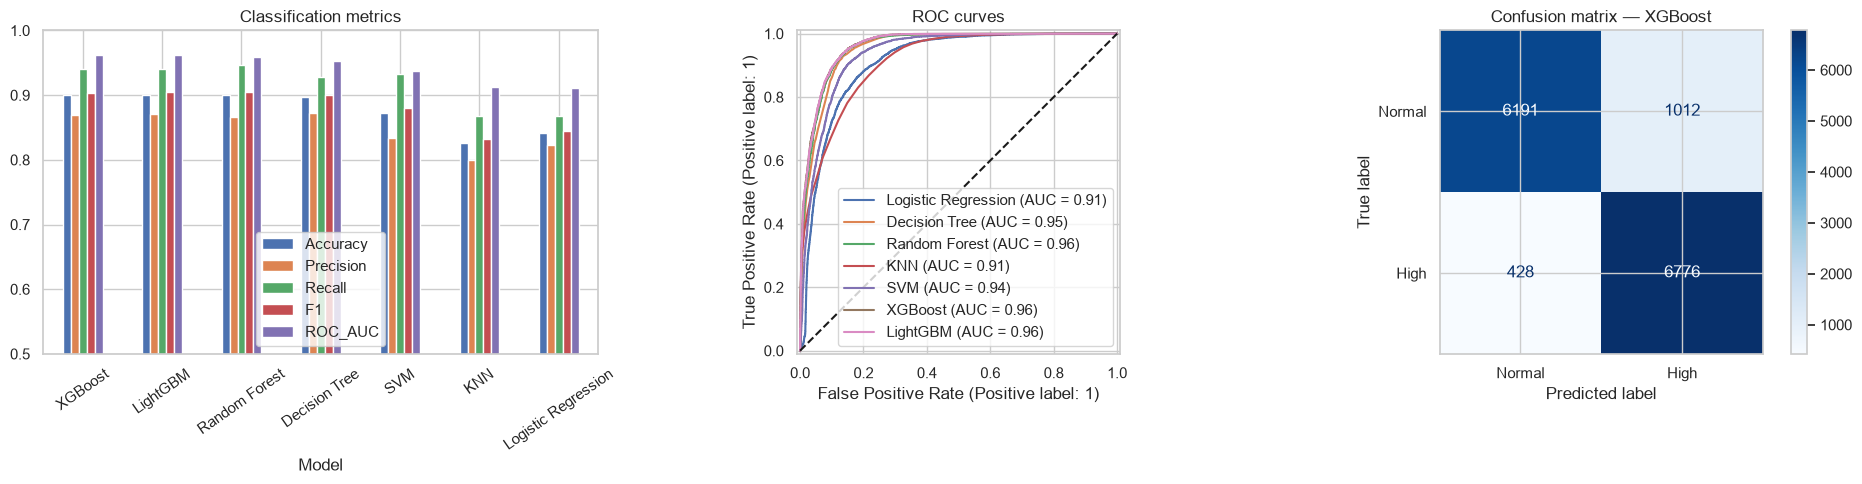

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
clf_res[['Accuracy','Precision','Recall','F1','ROC_AUC']].plot.bar(ax=ax[0], rot=35); ax[0].set_ylim(.5, 1); ax[0].set_title('Classification metrics')
for n, p in clf_fit.items(): RocCurveDisplay.from_estimator(p, Xte, yte, name=n, ax=ax[1])
ax[1].plot([0,1],[0,1],'k--'); ax[1].set_title('ROC curves')
ConfusionMatrixDisplay.from_predictions(yte, clf_fit[best_clf].predict(Xte), display_labels=['Normal','High'], cmap='Blues', ax=ax[2]); ax[2].set_title(f'Confusion matrix — {best_clf}')
plt.tight_layout(); plt.show()

## 4. Handling class imbalance
**Step 1: check.** The median split is balanced by construction.

In [9]:
vc = df['HighDemand'].value_counts().sort_index()
print(pd.DataFrame({'count': vc, 'share': (vc/len(df)).round(4)}).rename(index={0:'Normal', 1:'High'}))
print(f'Majority:minority = {vc.max()/vc.min():.3f} -> balanced, resampling not required for the median target.')

            count  share
HighDemand              
Normal      36013    0.5
High        36018    0.5
Majority:minority = 1.000 -> balanced, resampling not required for the median target.


**Step 2: demonstrate on a genuinely imbalanced target.** *Very high demand* = Demand ≥ 90th percentile (≈10% of sessions). Samplers are applied **inside the training pipeline only**, so the test set stays untouched. Accuracy is misleading here, so compare Recall, F1 and PR-AUC.

In [10]:
thr90 = df['Demand'].quantile(.9); y90 = (df['Demand'] >= thr90).astype(int)
print(f'90th percentile = {thr90:.2f} kWh | positive share = {y90.mean():.3f}')
Xa, Xb, ya, yb = train_test_split(df[FEATURES], y90, test_size=0.2, stratify=y90, random_state=RS)
base_models = {'Logistic Regression': (True, LogisticRegression(max_iter=2000, random_state=RS)),
               'Random Forest': (False, RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=RS)),
               'LightGBM': (False, LGBMClassifier(n_estimators=300, learning_rate=0.05, subsample=.8, subsample_freq=1, colsample_bytree=.8, n_jobs=-1, random_state=RS, verbose=-1))}
strategies = {'None': None, 'class_weight=balanced': 'cw', 'Random Oversampling': RandomOverSampler(random_state=RS), 'SMOTE': SMOTE(random_state=RS), 'ADASYN': ADASYN(random_state=RS)}
rows = []
for mn, (sc, est) in base_models.items():
    for sn, smp in strategies.items():
        e = clone(est)
        if smp == 'cw':
            e.set_params(**({'class_weight': 'balanced'} if mn != 'LightGBM' else {'class_weight': 'balanced'})); steps = [('p', prep(sc)), ('m', e)]
        else: steps = [('p', prep(sc))] + ([('s', smp)] if smp is not None else []) + [('m', e)]
        pipe = ImbPipeline(steps).fit(Xa, ya); rows.append({'Model': mn, 'Strategy': sn, **cscore(pipe, Xb, yb)})
imb = pd.DataFrame(rows).set_index(['Model', 'Strategy']); imb.round(4)

90th percentile = 37.61 kWh | positive share = 0.100


Accuracy  Precision  Recall  \
Model               Strategy                                             
Logistic Regression None                     0.9278     0.7206  0.4545   
                    class_weight=balanced    0.9230     0.5715  0.9181   
                    Random Oversampling      0.9229     0.5715  0.9153   
                    SMOTE                    0.9257     0.5818  0.9160   
                    ADASYN                   0.8520     0.4015  0.9778   
Random Forest       None                     0.9600     0.8214  0.7661   
                    class_weight=balanced    0.9401     0.6348  0.9445   
                    Random Oversampling      0.9451     0.6590  0.9348   
                    SMOTE                    0.9563     0.7388  0.8716   
                    ADASYN                   0.9533     0.7108  0.8987   
LightGBM            None                     0.9624     0.8196  0.8008   
                    class_weight=balanced    0.9426     0.6455  0.9452   
                    Random Oversampling      0.9447     0.6554  0.9438   
                    SMOTE                    0.9618     0.8029  0.8196   
                    ADASYN                   0.9611     0.7885  0.8355   

                                               F1  ROC_AUC  PR_AUC  
Model               Strategy                                        
Logistic Regression None                   0.5574   0.9518  0.6002  
                    class_weight=balanced  0.7045   0.9640  0.6176  
                    Random Oversampling    0.7037   0.9639  0.6173  
                    SMOTE                  0.7116   0.9644  0.6184  
                    ADASYN                 0.5693   0.9643  0.6126  
Random Forest       None                   0.7928   0.9803  0.8708  
                    class_weight=balanced  0.7593   0.9811  0.8608  
                    Random Oversampling    0.7730   0.9813  0.8695  
                    SMOTE                  0.7997   0.9814  0.8641  
                    ADASYN                 0.7937   0.9813  0.8573  
LightGBM            None                   0.8101   0.9839  0.8877  
                    class_weight=balanced  0.7671   0.9834  0.8798  
                    Random Oversampling    0.7736   0.9845  0.8806  
                    SMOTE                  0.8111   0.9844  0.8823  
                    ADASYN                 0.8113   0.9845  0.8822

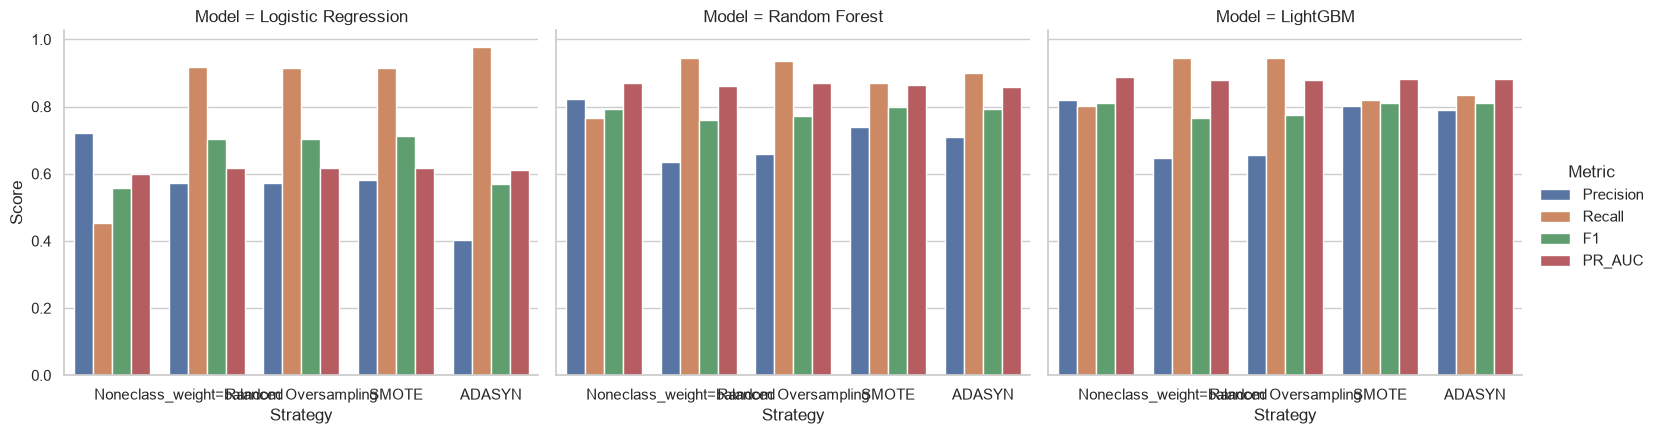

In [11]:
g = imb.reset_index().melt(id_vars=['Model','Strategy'], value_vars=['Precision','Recall','F1','PR_AUC'], var_name='Metric', value_name='Score')
sns.catplot(data=g, x='Strategy', y='Score', hue='Metric', col='Model', kind='bar', height=4.5, aspect=1.15); plt.show()

**Reading:** oversampling and class weights trade precision for recall (more true high-demand sessions found, more false alarms). Ranking quality (ROC-AUC / PR-AUC) barely changes. Pick the strategy by the cost of a missed high-demand session versus a false alarm.

## 5. Explainable AI — SHAP
Global and local explanations for the best regressor and best classifier. One-hot `Location` columns are shown individually here.

In [12]:
def parts(pipe, X):
    Z = pipe.named_steps['p'].transform(X); Z = Z.toarray() if hasattr(Z, 'toarray') else np.asarray(Z)
    names = [n.split('__', 1)[1] for n in pipe.named_steps['p'].get_feature_names_out()]
    return pd.DataFrame(Z, columns=names)
reg_p, clf_p = reg_fit[best_reg], clf_fit[best_clf]
Xs = df[FEATURES].sample(2000, random_state=RS)
Zr, Zc = parts(reg_p, Xs), parts(clf_p, Xs)
exp_r, exp_c = shap.TreeExplainer(reg_p.named_steps['m']), shap.TreeExplainer(clf_p.named_steps['m'])
sv_r = exp_r.shap_values(Zr); sv_c = exp_c.shap_values(Zc); sv_c = sv_c[1] if isinstance(sv_c, list) else sv_c
print('Regression:', best_reg, '| Classification:', best_clf)

Regression: XGBoost | Classification: XGBoost


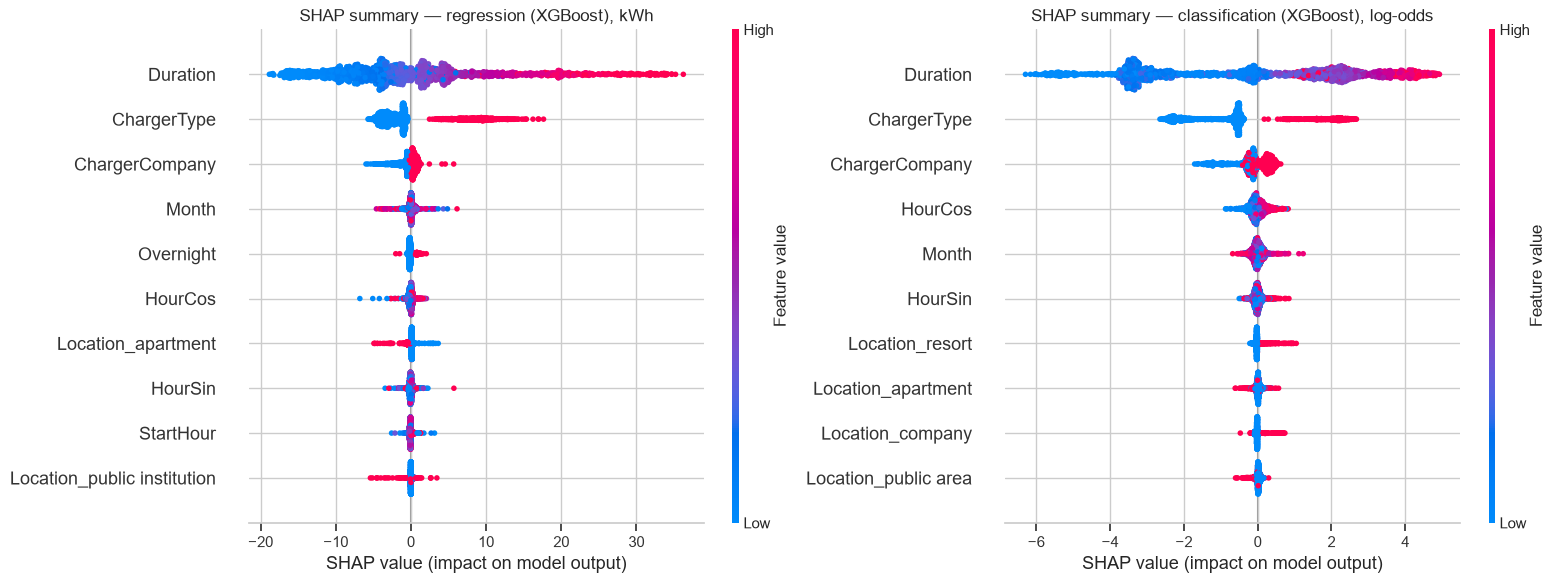

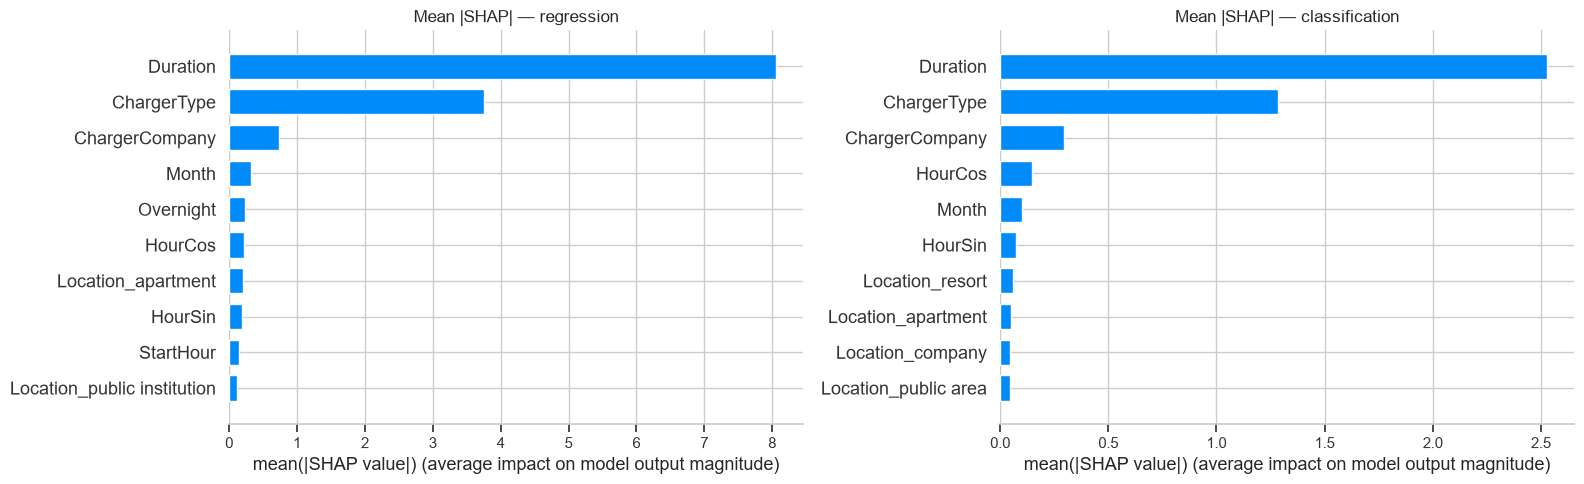

In [13]:
fig = plt.figure(figsize=(16, 6))
plt.subplot(1,2,1); shap.summary_plot(sv_r, Zr, show=False, max_display=10, plot_size=None); plt.title(f'SHAP summary — regression ({best_reg}), kWh')
plt.subplot(1,2,2); shap.summary_plot(sv_c, Zc, show=False, max_display=10, plot_size=None); plt.title(f'SHAP summary — classification ({best_clf}), log-odds')
plt.tight_layout(); plt.show()
fig = plt.figure(figsize=(16, 5))
plt.subplot(1,2,1); shap.summary_plot(sv_r, Zr, plot_type='bar', show=False, max_display=10, plot_size=None); plt.title('Mean |SHAP| — regression')
plt.subplot(1,2,2); shap.summary_plot(sv_c, Zc, plot_type='bar', show=False, max_display=10, plot_size=None); plt.title('Mean |SHAP| — classification')
plt.tight_layout(); plt.show()

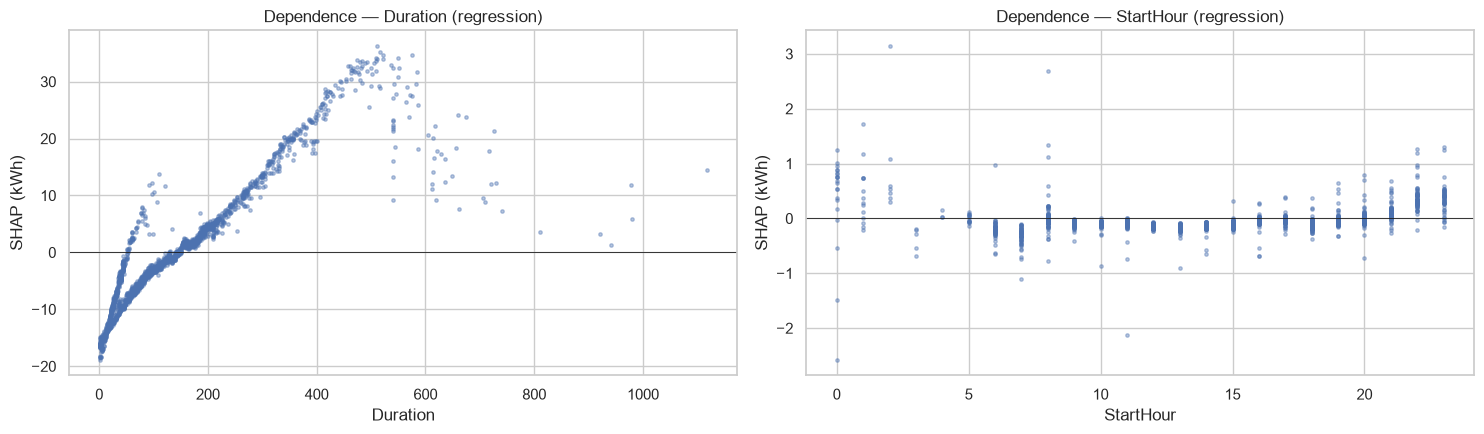

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, f in zip(ax, ['Duration', 'StartHour']):
    a.scatter(Zr[f], sv_r[:, Zr.columns.get_loc(f)], s=6, alpha=.4); a.axhline(0, color='k', lw=.6); a.set_xlabel(f); a.set_ylabel('SHAP (kWh)'); a.set_title(f'Dependence — {f} (regression)')
plt.tight_layout(); plt.show()

**Local explanations** — one high-demand and one normal-demand session from the test set, explained for the classifier.

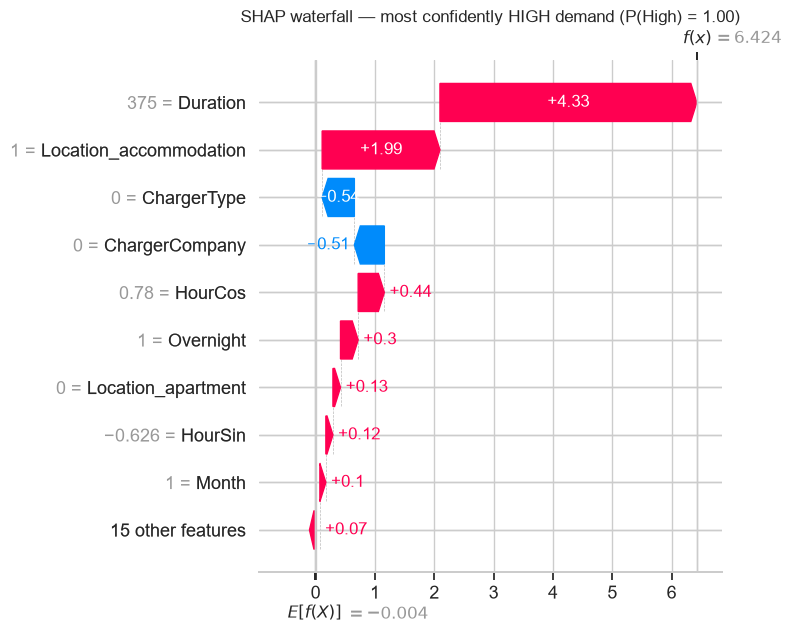

,Duration,StartHour,HourSin,HourCos,DayOfWeek,IsWeekend,Month,Overnight,ChargerType,ChargerCompany,Location
18748,375,21,-0.625923,0.779884,5,1,1,1,0,0,accommodation


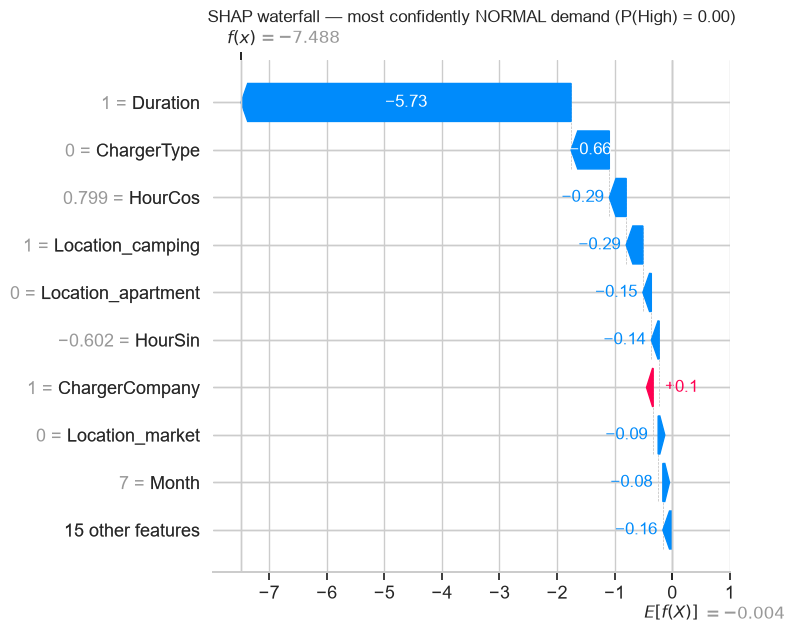

,Duration,StartHour,HourSin,HourCos,DayOfWeek,IsWeekend,Month,Overnight,ChargerType,ChargerCompany,Location
51953,1,21,-0.601815,0.798636,4,0,7,0,0,1,camping


In [15]:
Xt = Xte.copy(); pc = clf_p.predict_proba(Xt)[:, 1]
i_high = int(np.argmax(pc)); i_norm = int(np.argmin(pc)); Zt = parts(clf_p, Xt)
sv_t = exp_c.shap_values(Zt.iloc[[i_high, i_norm]]); sv_t = sv_t[1] if isinstance(sv_t, list) else sv_t
base = exp_c.expected_value; base = float(base[1] if np.ndim(base) else base)
for k, (idx, lab) in enumerate([(i_high, 'most confidently HIGH demand'), (i_norm, 'most confidently NORMAL demand')]):
    shap.plots.waterfall(shap.Explanation(sv_t[k], base, Zt.iloc[idx].values, feature_names=list(Zt.columns)), max_display=10, show=False)
    plt.title(f'SHAP waterfall — {lab} (P(High) = {pc[idx]:.2f})'); plt.tight_layout(); plt.show()
    display(Xt.iloc[[idx]])

## 6. Explainable AI — LIME
LIME fits a small interpretable model around one prediction. It is used here on the same two sessions and, for contrast, on a regression prediction.

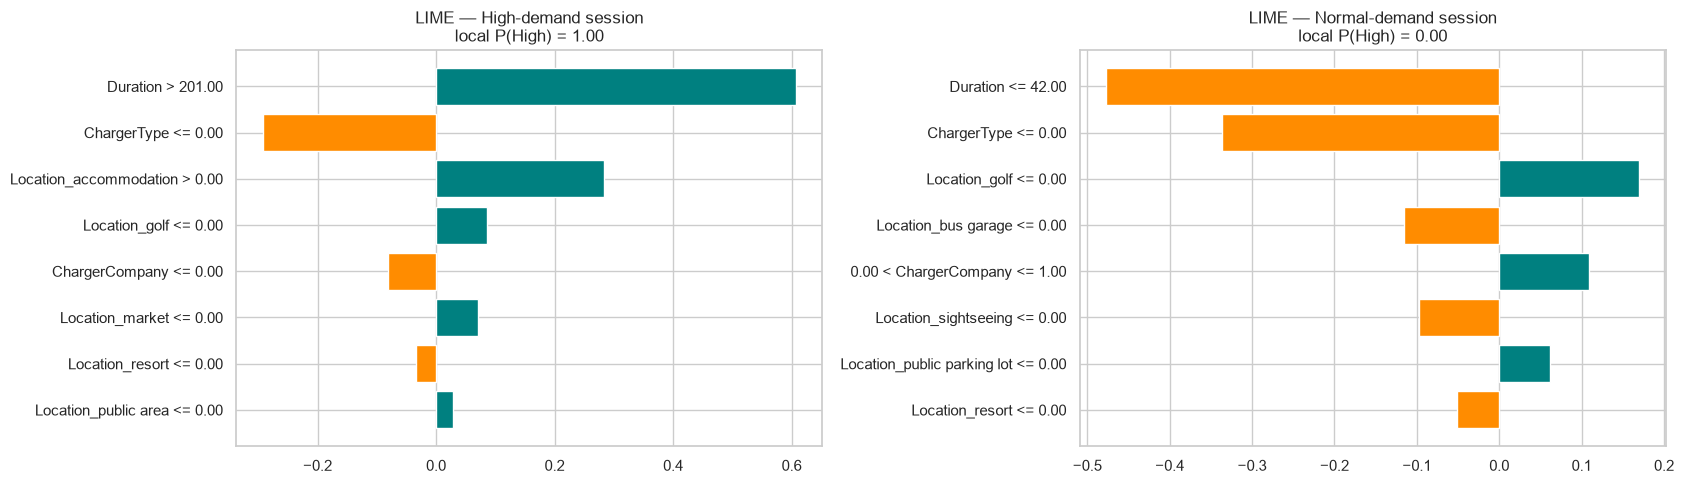

In [16]:
bg = parts(clf_p, df[FEATURES].sample(2000, random_state=RS))
lime_c = LimeTabularExplainer(bg.values, feature_names=list(bg.columns), class_names=['Normal','High'], mode='classification', discretize_continuous=True, random_state=RS)
fn_c = lambda a: clf_p.named_steps['m'].predict_proba(pd.DataFrame(a, columns=bg.columns))
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for a, (idx, lab) in zip(ax, [(i_high, 'High-demand session'), (i_norm, 'Normal-demand session')]):
    e = lime_c.explain_instance(Zt.iloc[idx].values, fn_c, num_features=8, num_samples=2000)
    d = pd.DataFrame(e.as_list(), columns=['Condition', 'Weight']).iloc[::-1]
    a.barh(d['Condition'], d['Weight'], color=['teal' if w > 0 else 'darkorange' for w in d['Weight']]); a.set_title(f'LIME — {lab}\nlocal P(High) = {e.predict_proba[1]:.2f}')
plt.tight_layout(); plt.show()

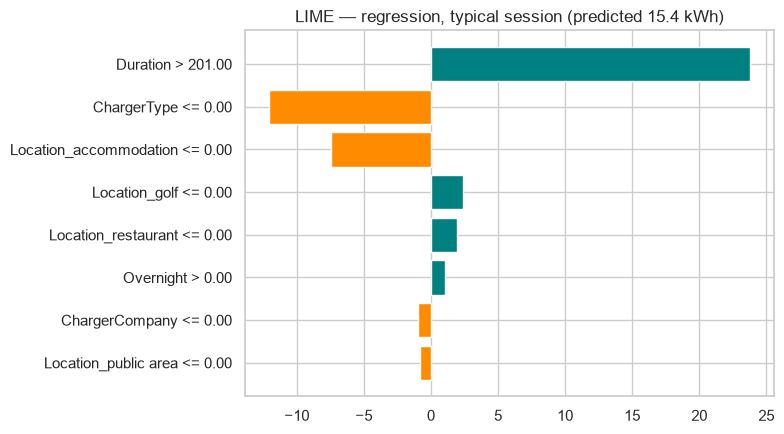

In [17]:
bg_r = parts(reg_p, df[FEATURES].sample(2000, random_state=RS))
lime_r = LimeTabularExplainer(bg_r.values, feature_names=list(bg_r.columns), mode='regression', discretize_continuous=True, random_state=RS)
fn_r = lambda a: reg_p.named_steps['m'].predict(pd.DataFrame(a, columns=bg_r.columns))
Zr_te = parts(reg_p, Xte); j = int(np.argsort(reg_p.predict(Xte))[len(Xte)//2])   # a typical (median-prediction) session
e = lime_lime = lime_r.explain_instance(Zr_te.iloc[j].values, fn_r, num_features=8, num_samples=2000)
d = pd.DataFrame(e.as_list(), columns=['Condition','Weight']).iloc[::-1]
plt.figure(figsize=(8,4.5)); plt.barh(d['Condition'], d['Weight'], color=['teal' if w > 0 else 'darkorange' for w in d['Weight']]); plt.title(f'LIME — regression, typical session (predicted {reg_p.predict(Xte.iloc[[j]])[0]:.1f} kWh)'); plt.tight_layout(); plt.show()

### SHAP vs LIME
- **SHAP** gives consistent global *and* local explanations (summary, dependence, waterfall) that add up to the prediction. It is fast for tree models.
- **LIME** is a local linear approximation: easy to read for one session, but results vary a little between runs and it has no global view.
- Both put `Duration` and `ChargerType` first, which gives confidence in the explanation; smaller effects (location, company) are less stable in LIME.

## 7. Summary

In [18]:
from IPython.display import Markdown
shap_top = pd.Series(np.abs(sv_c).mean(0), index=Zc.columns).sort_values(ascending=False).head(3).index.tolist()
b, r = clf_res.loc[best_clf], reg_res.loc[best_reg]
Markdown(f'''
- **Regression:** best = **{best_reg}** (RMSE {r.RMSE:.2f} kWh, MAE {r.MAE:.2f}, R² {r.R2:.3f}).
- **Classification:** best = **{best_clf}** (Accuracy {b.Accuracy:.3f}, F1 {b.F1:.3f}, ROC-AUC {b.ROC_AUC:.3f}).
- **Class imbalance:** the median target is balanced (50/50). On a 10% positive target, resampling and class weights raise recall at the cost of precision, with little change in ROC/PR-AUC.
- **Explainability:** SHAP ranks **{shap_top[0]}**, **{shap_top[1]}**, **{shap_top[2]}** as the main drivers of high-demand sessions; LIME on individual sessions points to the same leading factors (Duration, then ChargerType), with location and company playing smaller roles.
- **Caveat:** `Duration` is only known after a session ends, so these models explain/estimate demand for a session of a given length; they are not plug-in-time forecasts.
''')


- **Regression:** best = **XGBoost** (RMSE 5.85 kWh, MAE 3.31, R² 0.811).
- **Classification:** best = **XGBoost** (Accuracy 0.900, F1 0.904, ROC-AUC 0.962).
- **Class imbalance:** the median target is balanced (50/50). On a 10% positive target, resampling and class weights raise recall at the cost of precision, with little change in ROC/PR-AUC.
- **Explainability:** SHAP ranks **Duration**, **ChargerType**, **ChargerCompany** as the main drivers of high-demand sessions; LIME on individual sessions points to the same leading factors (Duration, then ChargerType), with location and company playing smaller roles.
- **Caveat:** `Duration` is only known after a session ends, so these models explain/estimate demand for a session of a given length; they are not plug-in-time forecasts.
